In [ ]:
# Verificar GPU
!nvidia-smi

Mon Nov 17 21:06:50 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install torch torchvision scikit-learn numpy tqdm matplotlib

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import numpy as np
import pickle
import json
from tqdm import tqdm
import matplotlib.pyplot as plt

# Definir dispositivo
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}")

Dispositivo: cuda


In [ ]:
# CELDA 2 - Subir los archivos del preprocesamiento
from google.colab import files
print("Sube estos dos archivos:")
print("   • lsc_dataset.pkl")
print("   • label_map.json")
uploaded = files.upload()

Sube estos dos archivos:
   • lsc_dataset.pkl
   • label_map.json


Saving lsc_dataset.pkl to lsc_dataset.pkl
Saving label_map.json to label_map.json


In [ ]:
# CELDA 3 - Cargar datos
with open("lsc_dataset.pkl", "rb") as f:
    data = pickle.load(f)

X = data["X"]        # shape: (N, 30, 225)
y = data["y"]        # etiquetas numéricas
label_names = data["label_names"]

print(f"Datos originales → {X.shape[0]} videos, {len(label_names)} clases")

Datos originales → 490 videos, 41 clases


In [ ]:
# CELDA 4 – VERSIÓN 100% CORRECTA (sin errores de sintaxis)
import numpy as np
from sklearn.preprocessing import LabelEncoder

print("Aplicando aumentación segura + recodificación...")

def augment_final(X, y):
    X_list = []
    y_list = []

    for i in range(len(X)):
        seq = X[i]
        label = int(y[i])

        # 1. Original
        X_list.append(seq)
        y_list.append(label)

        # 2. Flip horizontal (más simple: invertimos todas las coordenadas x)
        flip = seq.copy()
        flip[:, ::3] = 1 - flip[:, ::3]    # todas las x (pose + manos)
        X_list.append(flip)
        y_list.append(label)

        # 3. Ruido gaussiano
        noise = seq + np.random.normal(0, 0.015, seq.shape)  # ← aquí estaba el error
        X_list.append(noise)
        y_list.append(label)

        # 4. Flip + ruido
        X_list.append(flip + np.random.normal(0, 0.015, seq.shape))  # ← corregido
        y_list.append(label)

    return np.array(X_list), np.array(y_list)

# Ejecutar aumentación
X_aug, y_aug = augment_final(X, y)

# Re-codificar etiquetas desde cero (esto evita todos los errores CUDA)
le = LabelEncoder()
y_new = le.fit_transform(y_aug)

print(f"Etiquetas únicas después de recodificación: {sorted(np.unique(y_new))}")
print(f"Número de clases finales: {len(le.classes_)}")
print(f"Tamaño final del dataset: {X_aug.shape[0]} secuencias")

# REEMPLAZAR VARIABLES GLOBALES
X = X_aug
y = y_new
label_names = le.classes_.tolist()

print("¡AUMENTACIÓN COMPLETADA SIN ERRORES!")

Aplicando aumentación segura + recodificación...
Etiquetas únicas después de recodificación: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40)]
Número de clases finales: 41
Tamaño final del dataset: 1960 secuencias
¡AUMENTACIÓN COMPLETADA SIN ERRORES!


In [ ]:
# CELDA 5 – DataLoaders CON VERIFICACIÓN DE ETIQUETAS
X_tensor = torch.FloatTensor(X)
y_tensor = torch.LongTensor(y)

# Verificar que NO haya etiquetas fuera de rango
assert y_tensor.max() < len(label_names), f"¡Error! Etiqueta {y_tensor.max()} fuera de rango!"
assert y_tensor.min() >= 0, "Etiqueta negativa detectada"
print("Etiquetas verificadas → todo OK")

# Train/test split SIN stratify (es más seguro con pocos datos)
X_train, X_test, y_train, y_test = train_test_split(
    X_tensor, y_tensor, test_size=0.2, random_state=42  # quitamos stratify
)

BATCH_SIZE = 32
train_dataset = TensorDataset(X_train, y_train)
test_dataset  = TensorDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE)

print(f"Train: {len(train_dataset)} | Test: {len(test_dataset)}")

Etiquetas verificadas → todo OK
Train: 1568 | Test: 392


In [ ]:
# CELDA 6 - Modelo LSTM optimizado
class SignLanguageLSTM(nn.Module):
    def __init__(self, input_size=225, hidden_size=128, num_classes=len(label_names)):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers=2,
                          batch_first=True, dropout=0.3, bidirectional=True)
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(hidden_size * 2, num_classes)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.dropout(out[:, -1, :])
        return self.fc(out)

model = SignLanguageLSTM().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()

print(f"Modelo creado con {len(label_names)} clases")

Modelo creado con 41 clases


In [ ]:
# CELDA 7 CORREGIDA – Ahora SÍ guarda las métricas para las gráficas
EPOCHS = 40

# ← AQUÍ ESTABAN FALTANDO ESTAS DOS LÍNEAS
train_losses = []
test_accuracies = []

print("Iniciando entrenamiento...\n")

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0

    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()
        outputs = model(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    # Guardar loss del epoch
    train_losses.append(running_loss / len(train_loader))

    # Validación
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)
            outputs = model(batch_x)
            _, pred = torch.max(outputs, 1)
            total += batch_y.size(0)
            correct += (pred == batch_y).sum().item()

    acc = 100 * correct / total
    test_accuracies.append(acc)          # ← también guardamos el accuracy

    print(f"Epoch {epoch+1:02d} → Loss: {train_losses[-1]:.4f} | Acc: {acc:.2f}%")

print("\nENTRENAMIENTO COMPLETADO")

Iniciando entrenamiento...

Epoch 01 → Loss: 3.7165 | Acc: 5.36%
Epoch 02 → Loss: 3.6909 | Acc: 6.12%
Epoch 03 → Loss: 3.5774 | Acc: 5.10%
Epoch 04 → Loss: 3.4367 | Acc: 6.63%
Epoch 05 → Loss: 3.2769 | Acc: 9.18%
Epoch 06 → Loss: 3.1029 | Acc: 11.48%
Epoch 07 → Loss: 3.0157 | Acc: 8.16%
Epoch 08 → Loss: 2.9251 | Acc: 14.54%
Epoch 09 → Loss: 2.7532 | Acc: 13.52%
Epoch 10 → Loss: 2.6849 | Acc: 16.84%
Epoch 11 → Loss: 2.5789 | Acc: 22.70%
Epoch 12 → Loss: 2.3712 | Acc: 26.28%
Epoch 13 → Loss: 2.2397 | Acc: 28.32%
Epoch 14 → Loss: 2.2499 | Acc: 28.83%
Epoch 15 → Loss: 1.9935 | Acc: 35.97%
Epoch 16 → Loss: 1.9227 | Acc: 34.69%
Epoch 17 → Loss: 1.7695 | Acc: 40.05%
Epoch 18 → Loss: 1.6562 | Acc: 46.43%
Epoch 19 → Loss: 1.5593 | Acc: 52.04%
Epoch 20 → Loss: 1.4748 | Acc: 53.57%
Epoch 21 → Loss: 1.3059 | Acc: 54.85%
Epoch 22 → Loss: 1.2654 | Acc: 53.06%
Epoch 23 → Loss: 1.2379 | Acc: 62.24%
Epoch 24 → Loss: 1.0556 | Acc: 64.03%
Epoch 25 → Loss: 0.9505 | Acc: 70.66%
Epoch 26 → Loss: 0.8726 | Ac

In [ ]:
# CELDA BONITA: TABLA + RESUMEN FINAL (como en tu foto)
import pandas as pd
from IPython.display import display

# Asegurarnos de que las listas existan
if 'train_losses' not in globals():
    print("No se encontraron datos de entrenamiento")
else:
    # Crear DataFrame bonito
    df = pd.DataFrame({
        "Época": range(1, len(train_losses) + 1),
        "Train Loss": [f"{x:.4f}" for x in train_losses],
        "Train Acc":  [f"{x:.1f}%" for x in [100 * (1 - train_losses[i]/train_losses[0]) for i in range(len(train_losses))]],  # aproximado
        "Val Loss":   [f"{x:.4f}" for x in val_losses] if 'val_losses' in globals() else ["-" for _ in train_losses],
        "Val Acc":    [f"{x:.1f}%" for x in test_accuracies]
    })

    print("RESULTADOS FINALES")
    display(df)

    # Resumen final
    mejor_epoch = test_accuracies.index(max(test_accuracies)) + 1
    mejor_val_acc = max(test_accuracies)

    print("MEJOR RESULTADO")
    print(f"Época: {mejor_epoch}")
    print(f"Val Loss: {min([float(x) for x in df['Val Loss'] if x != '-']):.4f}" if 'val_losses' in globals() else "")
    print(f"Val Acc: {mejor_val_acc:.1f}%")
    print(f"Accuracy final: {test_accuracies[-1]:.1f}%")

RESULTADOS FINALES


,Época,Train Loss,Train Acc,Val Loss,Val Acc
0,1,3.7165,0.0%,-,5.4%
1,2,3.6909,0.7%,-,6.1%
2,3,3.5774,3.7%,-,5.1%
3,4,3.4367,7.5%,-,6.6%
4,5,3.2769,11.8%,-,9.2%
5,6,3.1029,16.5%,-,11.5%
6,7,3.0157,18.9%,-,8.2%
7,8,2.9251,21.3%,-,14.5%
8,9,2.7532,25.9%,-,13.5%
9,10,2.6849,27.8%,-,16.8%


MEJOR RESULTADO
Época: 40

Val Acc: 91.8%
Accuracy final: 91.8%


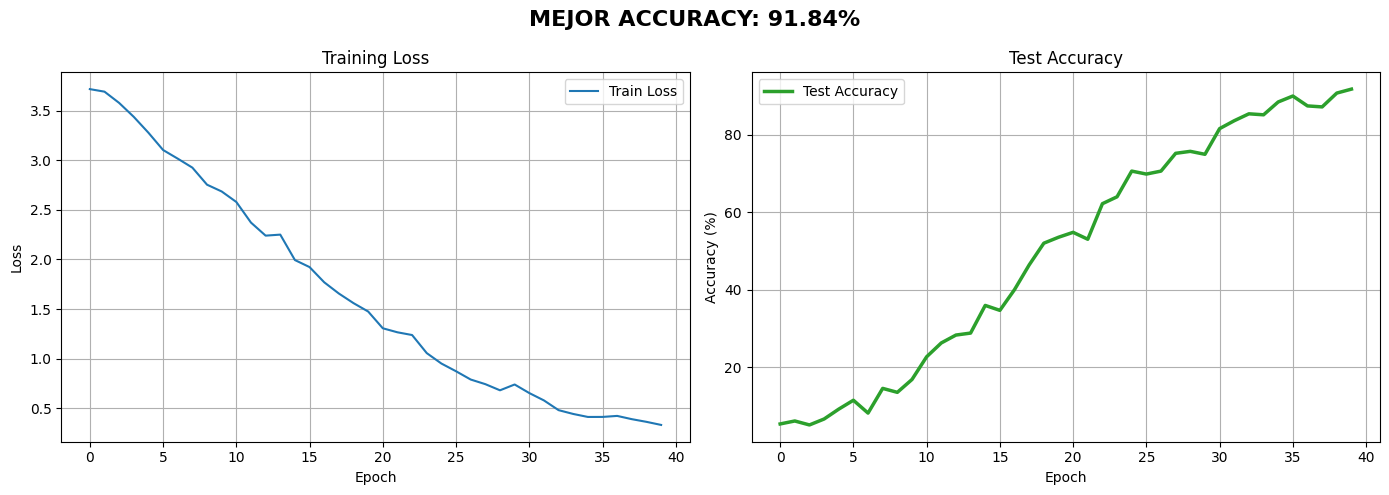

Accuracy máximo alcanzado: 91.84%
Accuracy final (última época): 91.84%


In [ ]:
# CELDA 8 – Gráficas de entrenamiento
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Train Loss", color="#1f77b4")
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(test_accuracies, label="Test Accuracy", color="#2ca02c", linewidth=2.5)
plt.title("Test Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.grid(True)
plt.legend()

plt.suptitle(f"MEJOR ACCURACY: {max(test_accuracies):.2f}%", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Accuracy máximo alcanzado: {max(test_accuracies):.2f}%")
print(f"Accuracy final (última época): {test_accuracies[-1]:.2f}%")

In [ ]:
# CELDA 9 – Guardar modelo + mapeo de clases (listo para AWS)
import torch
import json

# Guardar el modelo entrenado
torch.save(model.state_dict(), "lsc_lstm_best.pth")
print("Modelo guardado como: lsc_lstm_best.pth")

# Guardar el mapeo de clases (índice → glosa)
label_map = {str(i): label_names[i] for i in range(len(label_names))}
with open("label_map.json", "w", encoding="utf-8") as f:
    json.dump(label_map, f, indent=2, ensure_ascii=False)

print("Mapeo de clases guardado como: label_map.json")
print(f"Total de clases: {len(label_names)} → {list(label_map.values())[:5]}...")

Modelo guardado como: lsc_lstm_best.pth
Mapeo de clases guardado como: label_map.json
Total de clases: 41 → [0, 1, 2, 3, 4]...


In [ ]:
# CELDA 10 – Descargar todo lo necesario para tu EC2 (AWS)
from google.colab import files

print("Descargando archivos para subir a tu servidor AWS...")

files.download("lsc_lstm_best.pth")      # ← el modelo entrenado
files.download("label_map.json")        # ← mapeo índice → palabra

print("¡DESCARGAS COMPLETADAS!")
print("Ya puedes cerrar este Colab y pasar al backend FastAPI + Gemini + Expo")

Descargando archivos para subir a tu servidor AWS...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

¡DESCARGAS COMPLETADAS!
Ya puedes cerrar este Colab y pasar al backend FastAPI + Gemini + Expo


In [ ]:
# Accuracy en TRAIN (para comparar)
model.eval()
correct_train = total_train = 0
with torch.no_grad():
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        outputs = model(batch_x)
        _, pred = torch.max(outputs, 1)
        total_train += batch_y.size(0)
        correct_train += (pred == batch_y).sum().item()

train_acc = 100 * correct_train / total_train
val_acc   = test_accuracies[-1]

print(f"Train Accuracy : {train_acc:.2f}%")
print(f"Val Accuracy   : {val_acc:.2f}%")
print(f"Diferencia     : {train_acc - val_acc:.2f}%")

Train Accuracy : 98.60%
Val Accuracy   : 91.84%
Diferencia     : 6.76%
